# Tech Layoff and Hiring Trend Tracker

Which tech sectors recorded the most job losses, and how did hiring or recruitment demand change around their layoff peaks?

The historical series starts in March 2020. The sector and funding-stage comparisons use 1 June 2023 through 29 October 2026. The hiring case studies use each selected sector’s peak in its country-specific data, including earlier peaks.

**Sector losses.** Hardware led the post-emergency period with 79,495 reported losses.  
**Hiring.** U.S. durable-goods hires returned above their pre-peak average in June 2026, 14 months after the U.S.-tagged Hardware peak.  
**Funding stage.** Post-IPO records accounted for 338,249 reported losses during the post-emergency period.

## Sources and measures

| Cases | Source and measure | Comparison |
|---|---|---|
| All layoff analyses | Project snapshot `layoffs.csv`, 4,648 raw records. The `source` column identifies the reporting source for each announcement. | Sum the reviewed headcounts and report coverage. Country tags describe the announcement and can include losses across borders. |
| U.S. Retail and Hardware | BLS JOLTS monthly hires via FRED: [Retail Trade](https://fred.stlouisfed.org/series/JTS4400HIL) and [Durable Goods Manufacturing](https://fred.stlouisfed.org/series/JTS3200HIL). | Average monthly hires in the three months before each peak. Durable goods is a broader measure for Hardware. |
| U.S. Consumer | [BLS JOLTS Information hires via FRED](https://fred.stlouisfed.org/series/JTU5100HIL). | Same month one year earlier. Information provides context for the Consumer companies in the tracker. |
| India Education and Finance | Naukri JobSpeak industry indices from the [July 2023 report](https://www.infoedge.in/pdfs/News_Events_pdfs/Naukri-Jobspeak-July-2023.pdf) and [March 2025 report copy](https://www.scribd.com/document/878209043/Naukri-Jobspeak-March-2025). Values are transcribed in the case cells. | Compare recruitment demand with the preceding three-month average. |
| India Food | Vahan findings reported by *The Financial Express*, 22 November 2020. | Delivery-worker demand relative to pre-COVID conditions. The report provides a checkpoint. |
| Germany Food, Retail and Manufacturing | [Indeed Hiring Lab](https://github.com/hiring-lab/job_postings_tracker) daily new-postings indices, averaged monthly. Food uses Retail as a proxy. Manufacturing uses Production & Manufacturing. | Compare with the preceding three-month average and follow six months after the peak. |

### Running the notebook

Run in order with the original `layoffs.csv` beside the notebook or upload it when prompted in Colab. The corrections use the original row order. The U.S. and German cells retrieve external series and require internet access. Saved outputs reflect the project snapshot. Source revisions can change results on later runs. Optional CSV exports are grouped at the end.

## Data preparation and quality checks

In [ ]:
from pathlib import Path
import pandas as pd

input_path = Path("layoffs.csv")
if not input_path.is_file():
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Select the original layoffs.csv snapshot.")
    input_path = Path(next(iter(uploaded)))

layoffs = pd.read_csv(input_path)
print(f"Raw records: {len(layoffs):,}; columns: {len(layoffs.columns)}")
display(layoffs.head())

Saving layoffs.csv to layoffs.csv
Raw records: 4,648; columns: 11


,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
0,Pipedrive,"Tallinn, Non-U.S.",267.0,10/29/2026,NaN,Sales,https://news.err.ee/1610180296/estonian-unicor...,Private Equity,90.0,Estonia,10/30/2026
1,Dropbox,SF Bay Area,200.0,10/28/2026,0.09,Other,https://www.businessinsider.com/dropbox-layoff...,Post-IPO,1700.0,United States,10/30/2026
2,Front,SF Bay Area,NaN,10/27/2026,NaN,Support,https://www.linkedin.com/posts/droconnell_toda...,Series D,203.0,United States,10/28/2026
3,SolarEdge,"Tel Aviv, Non-U.S.",200.0,10/26/2026,NaN,Energy,https://www.calcalistech.com/ctechnews/article...,Post-IPO,155.0,Israel,10/27/2026
4,Loop,Austin,63.0,10/22/2026,NaN,Retail,https://www.linkedin.com/posts/hannah-bravo-54...,Series B,125.0,United States,10/23/2026


The initial dataset contains 4,648 records and 11 columns. Reported employee layoff counts are missing for 1,615 records (34.7%), workforce reduction percentages for 1,745 records (37.5%), and funds raised for 552 records (11.9%). Sector job-loss comparisons will include the available reported counts alongside their reporting coverage. Company and both date fields have zero detected missing values, with date validity still to be checked.

In [ ]:
# Summarise missing data.
missing_report = pd.DataFrame({
    "MissingRows": layoffs.isna().sum(),
    "MissingPercent": layoffs.isna().mean().mul(100).round(1)
}).sort_values("MissingRows", ascending=False)

print(missing_report.to_string())

# Inspect event dates while keeping the original column intact.
event_dates = pd.to_datetime(
    layoffs["date"],
    format="%m/%d/%Y",
    errors="coerce"
)

print("\nEarliest event date:", event_dates.min())
print("Latest event date:", event_dates.max())
print("Missing date values:", layoffs["date"].isna().sum())
print(
    "Present dates that failed conversion:",
    (layoffs["date"].notna() & event_dates.isna()).sum()
)

# Inspect repeated rows and industry labels.
print("\nExact duplicate rows:", layoffs.duplicated().sum())
print("\nRecords by industry:")
print(layoffs["industry"].value_counts(dropna=False).to_string())

                     MissingRows  MissingPercent
percentage_laid_off         1745            37.5
total_laid_off              1615            34.7
funds_raised                 552            11.9
stage                          8             0.2
source                         3             0.1
country                        2             0.0
industry                       2             0.0
location                       1             0.0
company                        0             0.0
date                           0             0.0
date_added                     0             0.0

Earliest event date: 2020-03-11 00:00:00
Latest event date: 2026-10-29 00:00:00
Missing date values: 0
Present dates that failed conversion: 0

Exact duplicate rows: 0

Records by industry:
industry
Finance           551
Retail            368
Healthcare        337
Consumer          319
Other             319
Transportation    277
Food              261
Marketing         225
Crypto            182
Security      

Recorded layoff dates span 11 March 2020 to 29 October 2026. All event dates parsed successfully, and the initial check found zero fully identical rows. Finance has the largest number of records (551), followed by Retail (368) and Healthcare (337). These counts describe the frequency of records in the dataset. Employee-loss totals and reporting coverage will be examined separately. The first and last years have partial calendar coverage.

In [ ]:
# Create a working copy for cleaning.
layoffs_clean = layoffs.copy()

# Remove surrounding spaces and recognise blank text as missing.
text_columns = layoffs_clean.select_dtypes(include="object").columns

for column in text_columns:
    layoffs_clean[column] = (
        layoffs_clean[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

# Convert the two date columns and report conversion problems.
for column in ["date", "date_added"]:
    original_dates = layoffs_clean[column]

    parsed_dates = pd.to_datetime(
        original_dates,
        format="%m/%d/%Y",
        errors="coerce"
    )

    failed = original_dates.notna() & parsed_dates.isna()
    print(f"{column} conversion failures: {failed.sum()}")

    layoffs_clean[column] = parsed_dates

# Identify repeated company/date combinations for review.
review_mask = layoffs_clean.duplicated(
    subset=["company", "date"],
    keep=False
)

review_rows = layoffs_clean.loc[
    review_mask,
    [
        "company", "date", "location", "country",
        "total_laid_off", "percentage_laid_off", "source"
    ]
].sort_values(["company", "date"])

print(f"\nRows after cleaning: {len(layoffs_clean):,}")
print(f"Exact duplicate rows after cleaning: {layoffs_clean.duplicated().sum()}")
print(f"Rows sharing a company and event date: {len(review_rows)}")

display(review_rows.head(20))

date conversion failures: 0
date_added conversion failures: 0

Rows after cleaning: 4,648
Exact duplicate rows after cleaning: 0
Rows sharing a company and event date: 44


,company,date,location,country,total_laid_off,percentage_laid_off,source
119,Amazon,2026-07-22,Port St. Lucie,United States,1110.0,NaN,https://www.msn.com/en-us/money/companies/amaz...
121,Amazon,2026-07-22,Seattle,United States,NaN,NaN,https://www.reuters.com/business/world-at-work...
3602,Anodot,2022-07-06,"Tel Aviv, Non-U.S.",Israel,35.0,0.27,https://www.calcalistech.com/ctechnews/article...
3604,Anodot,2022-07-06,"Tel Aviv, Non-U.S.",Israel,15.0,0.20,https://www.calcalistech.com/ctechnews/article...
3169,Beyond Meat,2022-10-14,Los Angeles,United States,200.0,0.19,https://www.cnbc.com/2022/10/14/beyond-meat-to...
3170,Beyond Meat,2022-10-14,Los Angeles,United States,200.0,0.19,https://www.fooddive.com/news/beyond-meat-layo...
4465,Bustle Digital Group,2020-04-03,New York City,United States,24.0,0.08,https://digiday.com/media/bustle-digital-group...
4466,Bustle Digital Group,2020-04-03,New York City,United States,19.0,NaN,https://www.adweek.com/media/bdg-input-mic-lay...
3711,Bybit,2022-06-20,"Singapore, Non-U.S.",Singapore,600.0,0.30,https://techcrunch.com/2022/06/20/bybit-crypto...
3718,Bybit,2022-06-20,"Singapore, Non-U.S.",Singapore,NaN,NaN,https://twitter.com/WuBlockchain/status/153880...


A company-and-event-date check flagged 44 rows for source review. These include matching layoff figures reported by different sources, conflicting figures, and different locations. Each flagged group requires review before deciding which records to combine or retain.

In [48]:
# Preserve the original data and its row numbers.
layoffs_audit = layoffs.copy(deep=True).reset_index(drop=True)
layoffs_audit.insert(0, "OriginalRow", layoffs_audit.index)

assert len(layoffs_audit) == 4648, "Dataset differs: stop and check."

# Each excluded record points to the record covering its announcement.
exclusions = pd.DataFrame([
    [489, 492, "Oracle", "101 jobs already included in row 492"],
    [493, 492, "Oracle", "188 jobs already included in row 492"],
    [1827, 1826, "FNZ", "Same source and layoff announcement"],
    [3841, 3840, "Terminus", "Same source and layoff announcement"],
], columns=[
    "OriginalRow", "CoveredByRow", "ExpectedCompany", "ExclusionReason"
])

# Check that the row numbers still identify the expected records.
for row in exclusions.itertuples(index=False):
    assert layoffs_audit.loc[row.OriginalRow, "company"] == row.ExpectedCompany
    assert layoffs_audit.loc[row.CoveredByRow, "company"] == row.ExpectedCompany

for first, second in [(1827, 1826), (3841, 3840)]:
    assert layoffs_audit.loc[first, "source"] == layoffs_audit.loc[second, "source"]

assert "20824135" in layoffs_audit.loc[489, "source"]
assert "20818166" in layoffs_audit.loc[493, "source"]
assert "dozens-of-pleasanton-workers" in layoffs_audit.loc[492, "source"]

layoffs_audit = layoffs_audit.merge(
    exclusions.drop(columns="ExpectedCompany"),
    on="OriginalRow",
    how="left",
    validate="one_to_one"
)

layoffs_audit["ExcludeConfirmed"] = (
    layoffs_audit["ExclusionReason"].notna()
)

# Working data: further cleaning is still required.
layoffs_staged = layoffs_audit.loc[
    ~layoffs_audit["ExcludeConfirmed"]
].copy()

print(f"Original rows preserved: {len(layoffs_audit):,}")
print(f"Confirmed exclusions: {layoffs_audit['ExcludeConfirmed'].sum()}")
print(f"Rows remaining for further cleaning: {len(layoffs_staged):,}")

display(layoffs_audit.loc[
    layoffs_audit["ExcludeConfirmed"],
    ["OriginalRow", "company", "CoveredByRow", "ExclusionReason"]
])

Original rows preserved: 4,648
Confirmed exclusions: 4
Rows remaining for further cleaning: 4,644


,OriginalRow,company,CoveredByRow,ExclusionReason
489,489,Oracle,492.0,101 jobs already included in row 492
493,493,Oracle,492.0,188 jobs already included in row 492
1827,1827,FNZ,1826.0,Same source and layoff announcement
3841,3841,Terminus,3840.0,Same source and layoff announcement


In [ ]:
date_corrections = [
    (3604, "Anodot",         "2023-05-07", "Report date proxy"),
    (3781, "Cazoo",          "2022-09-08", "Announcement date"),
    (3790, "Clearco",        "2022-08-30", "Report date proxy"),
    (2079, "Rapid",          "2023-05-05", "Report date proxy"),
    (3455, "Sendy",          "2022-10-05", "Report date proxy"),
    (1499, "Nomad Health",   "2023-02-09", "Report date proxy"),
    (3661, "StockX",         "2022-11-02", "Report date proxy"),
    (2386, "REE Automotive", "2025-06-04", "Report date proxy"),
]

# Preserve the original date column.
layoffs_audit["AnalysisDate"] = pd.to_datetime(
    layoffs_audit["date"], format="%m/%d/%Y", errors="raise"
)
layoffs_audit["DateBasis"] = "Dataset date - not individually verified"
layoffs_audit["DateChanged"] = False
layoffs_audit["DateEvidence"] = pd.Series(
    pd.NA, index=layoffs_audit.index, dtype="string"
)

for original_row, company, new_date, basis in date_corrections:
    mask = layoffs_audit["OriginalRow"].eq(original_row)

    assert mask.sum() == 1
    assert layoffs_audit.loc[mask, "company"].iloc[0] == company
    assert not layoffs_audit.loc[mask, "ExcludeConfirmed"].iloc[0]

    layoffs_audit.loc[mask, "AnalysisDate"] = pd.Timestamp(new_date)
    layoffs_audit.loc[mask, "DateBasis"] = basis
    layoffs_audit.loc[mask, "DateChanged"] = True
    layoffs_audit.loc[mask, "DateEvidence"] = layoffs_audit.loc[mask, "source"]

# Additional evidence for these two corrections.
layoffs_audit.loc[
    layoffs_audit["OriginalRow"].eq(3781), "DateEvidence"
] = (
    "https://cardealermagazine.co.uk/"
    "cazoo-to-pull-out-of-mainland-europe-to-focus-on-uk-market/271241"
)

layoffs_audit.loc[
    layoffs_audit["OriginalRow"].eq(3661), "DateEvidence"
] = (
    "https://www.complex.com/sneakers/a/riley-jones/"
    "stockx-layoffs-november-2022"
)

# Refresh the working data using the updated audit table.
layoffs_staged = layoffs_audit.loc[
    ~layoffs_audit["ExcludeConfirmed"]
].copy()

print(f"Date corrections: {layoffs_audit['DateChanged'].sum()}")
print(f"Rows remaining: {len(layoffs_staged):,}")

display(layoffs_audit.loc[
    layoffs_audit["DateChanged"],
    ["OriginalRow", "company", "date", "AnalysisDate", "DateBasis"]
])

Date corrections: 8
Rows remaining: 4,644


,OriginalRow,company,date,AnalysisDate,DateBasis
1499,1499,Nomad Health,10/20/2023,2023-02-09,Report date proxy
2079,2079,Rapid,4/25/2023,2023-05-05,Report date proxy
2386,2386,REE Automotive,2/9/2023,2025-06-04,Report date proxy
3455,3455,Sendy,8/2/2022,2022-10-05,Report date proxy
3604,3604,Anodot,7/6/2022,2023-05-07,Report date proxy
3661,3661,StockX,6/28/2022,2022-11-02,Report date proxy
3781,3781,Cazoo,6/7/2022,2022-09-08,Announcement date
3790,3790,Clearco,6/6/2022,2022-08-30,Report date proxy


In [ ]:
# These decisions follow source review, not just matching numbers.
additional_exclusions = [
    (3170, 3169, "Beyond Meat", 200),
    (3100, 3101, "Oda", 70),
    (3102, 3101, "Oda", 70),
]

for exclude_row, keep_row, company, count in additional_exclusions:
    exclude_mask = layoffs_audit["OriginalRow"].eq(exclude_row)
    keep_mask = layoffs_audit["OriginalRow"].eq(keep_row)

    # Confirm that we are handling the intended records.
    assert exclude_mask.sum() == keep_mask.sum() == 1
    assert layoffs_audit.loc[exclude_mask, "company"].iloc[0] == company
    assert layoffs_audit.loc[keep_mask, "company"].iloc[0] == company
    assert layoffs_audit.loc[exclude_mask, "total_laid_off"].iloc[0] == count
    assert layoffs_audit.loc[keep_mask, "total_laid_off"].iloc[0] == count
    assert not layoffs_audit.loc[keep_mask, "ExcludeConfirmed"].iloc[0]

    layoffs_audit.loc[exclude_mask, "ExcludeConfirmed"] = True
    layoffs_audit.loc[exclude_mask, "CoveredByRow"] = keep_row
    layoffs_audit.loc[exclude_mask, "ExclusionReason"] = (
        "Repeated report of the same reviewed announcement"
    )

# Refresh the working data, retaining the date corrections.
layoffs_staged = layoffs_audit.loc[
    ~layoffs_audit["ExcludeConfirmed"]
].copy()

print(f"Original rows preserved: {len(layoffs_audit):,}")
print(f"Total confirmed exclusions: {layoffs_audit['ExcludeConfirmed'].sum()}")
print(f"Rows remaining: {len(layoffs_staged):,}")
print(f"Date corrections preserved: {layoffs_staged['DateChanged'].sum()}")

display(layoffs_audit.loc[
    layoffs_audit["OriginalRow"].isin([3170, 3100, 3102]),
    ["OriginalRow", "company", "CoveredByRow", "ExclusionReason"]
])

Original rows preserved: 4,648
Total confirmed exclusions: 7
Rows remaining: 4,641
Date corrections preserved: 8


,OriginalRow,company,CoveredByRow,ExclusionReason
3100,3100,Oda,3101.0,Repeated report of the same reviewed announcement
3102,3102,Oda,3101.0,Repeated report of the same reviewed announcement
3170,3170,Beyond Meat,3169.0,Repeated report of the same reviewed announcement


In [ ]:
# Preserve total_laid_off; create a separate field for aggregation.
layoffs_audit["LayoffsForTotal"] = pd.to_numeric(
    layoffs_audit["total_laid_off"], errors="raise"
).astype("Float64")

layoffs_audit["CountBasis"] = "Dataset value - not individually verified"
layoffs_audit.loc[
    layoffs_audit["LayoffsForTotal"].isna(), "CountBasis"
] = "Not reported"

layoffs_audit["CountAdjusted"] = False
layoffs_audit["CountEvidence"] = pd.Series(
    pd.NA, index=layoffs_audit.index, dtype="string"
)

count_issues = [
    (127, "Samsung", 739,
     "739 affected roles includes relocations; layoff count unknown"),
    (3661, "StockX", 80,
     "Fewer than 80 reported; exact count unknown"),
    (2386, "REE Automotive", 100,
     "More than 100 reported; exact count unknown"),
]

for original_row, company, original_count, explanation in count_issues:
    mask = layoffs_audit["OriginalRow"].eq(original_row)

    assert mask.sum() == 1
    assert layoffs_audit.loc[mask, "company"].iloc[0] == company
    assert layoffs_audit.loc[mask, "total_laid_off"].iloc[0] == original_count
    assert not layoffs_audit.loc[mask, "ExcludeConfirmed"].iloc[0]

    layoffs_audit.loc[mask, "LayoffsForTotal"] = pd.NA
    layoffs_audit.loc[mask, "CountBasis"] = explanation
    layoffs_audit.loc[mask, "CountAdjusted"] = True
    layoffs_audit.loc[mask, "CountEvidence"] = layoffs_audit.loc[mask, "source"]

layoffs_audit.loc[
    layoffs_audit["OriginalRow"].eq(3661), "CountEvidence"
] = (
    "https://www.complex.com/sneakers/a/riley-jones/"
    "stockx-layoffs-november-2022"
)

layoffs_staged = layoffs_audit.loc[
    ~layoffs_audit["ExcludeConfirmed"]
].copy()

print(f"Counts adjusted: {layoffs_staged['CountAdjusted'].sum()}")
print(f"Records retained: {len(layoffs_staged):,}")
print(
    "Records without a count for totals:",
    layoffs_staged["LayoffsForTotal"].isna().sum()
)

display(layoffs_staged.loc[
    layoffs_staged["CountAdjusted"],
    ["company", "total_laid_off", "LayoffsForTotal", "CountBasis"]
])

Counts adjusted: 3
Records retained: 4,641
Records without a count for totals: 1617


,company,total_laid_off,LayoffsForTotal,CountBasis
127,Samsung,739.0,<NA>,739 affected roles includes relocations; layof...
2386,REE Automotive,100.0,<NA>,More than 100 reported; exact count unknown
3661,StockX,80.0,<NA>,Fewer than 80 reported; exact count unknown


In [ ]:
# Create analysis labels while preserving the original columns.
category_columns = {
    "industry": "Industry",
    "country": "CountryReported",
    "stage": "FundingStage"
}

for original, cleaned in category_columns.items():
    layoffs_audit[cleaned] = (
        layoffs_audit[original]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Unknown")
    )

layoffs_audit["CountryReported"] = (
    layoffs_audit["CountryReported"]
    .replace({"UAE": "United Arab Emirates"})
)

# Preserve all previous exclusions and corrections.
layoffs_staged = layoffs_audit.loc[
    ~layoffs_audit["ExcludeConfirmed"]
].copy()

category_summary = pd.DataFrame([
    {
        "Field": column,
        "Known categories": layoffs_staged.loc[
            layoffs_staged[column].ne("Unknown"), column
        ].nunique(),
        "Unknown records": layoffs_staged[column].eq("Unknown").sum()
    }
    for column in category_columns.values()
])

display(category_summary)
print(f"Records retained: {len(layoffs_staged):,}")

,Field,Known categories,Unknown records
0,Industry,30,2
1,CountryReported,66,2
2,FundingStage,15,784


Records retained: 4,641


## Reported layoffs by industry

### Full historical period

In [ ]:
jobs_by_industry = (
    layoffs_staged.groupby("Industry")["LayoffsForTotal"]
    .sum(min_count=1)
    .sort_values(ascending=False)
)

display(jobs_by_industry.head(10).rename("Reported job losses").to_frame())

,Reported job losses
Industry,
Other,116776.0
Retail,109828.0
Hardware,104793.0
Consumer,99054.0
Transportation,70923.0
Finance,65531.0
Food,52227.0
Healthcare,40680.0
Infrastructure,24835.0


From March 2020 through October 2026, Retail led the named sectors with 109,828 reported job losses, followed by Hardware (104,793) and Consumer (99,054). Retail and Hardware were separated by just 5,035 jobs. The largest total overall belonged to Other (116,776), a catch-all category spanning multiple businesses.

Headcount coverage matters when reading this ranking. Of the 4,641 retained records, 3,024 included a layoff count. The totals therefore measure reported job losses. Comparing the percentage of jobs lost in each sector would also require workforce figures.

### Which sector recorded the most job losses after the COVID-19 emergency?

We rank all countries together by the sum of reported job losses using the corrected analysis date. The window starts on 1 June 2023, the first full calendar month after WHO ended the international COVID-19 emergency on 5 May, and ends at the latest analysis date in the dataset. Earlier peaks contribute to the historical trend only. “Other” and “Unknown” appear in the overall ranking. The headline sector comes from the named industries. Coverage is the percentage of records with a usable headcount. [WHO date reference](https://www.who.int/europe/emergencies/situations/covid-19)

In [ ]:
post_emergency = layoffs_staged.loc[layoffs_staged['AnalysisDate'].ge('2023-06-01')]
sector_ranking = (post_emergency.groupby('Industry')['LayoffsForTotal']
    .agg(ReportedLosses=lambda x: x.sum(min_count=1), Records='size', WithCount='count')
    .sort_values('ReportedLosses', ascending=False))
sector_ranking['CoveragePct'] = (100 * sector_ranking['WithCount'] / sector_ranking['Records']).round(1)
print('Through', post_emergency['AnalysisDate'].max().date())
print(sector_ranking.to_string())

Through 2026-10-29
                ReportedLosses  Records  WithCount  CoveragePct
Industry                                                       
Hardware               79495.0       62         41         66.1
Other                  76306.0      163        101         62.0
Retail                 51986.0      145         90         62.1
Consumer               42714.0      186        119         64.0
Finance                33637.0      212        128         60.4
Transportation         32502.0      112         63         56.2
Infrastructure         18875.0       29         13         44.8
Food                   16880.0       99         56         56.6
HR                     10824.0       40         27         67.5
Manufacturing           9474.0       30         22         73.3
Energy                  9403.0       39         23         59.0
Sales                   9215.0       40         29         72.5
Healthcare              8902.0      125         73         58.4
Security             

**Post-emergency finding.**

From 1 June 2023 through 29 October 2026, Hardware led the tracker with **79,495 reported job losses**. The “Other” category ranked second overall with 76,306. Retail was the next named sector with 51,986, leaving Hardware ahead of Retail by 27,509.

Of the 62 Hardware records, 41 included a usable layoff count (66.1%). The ranking therefore reflects the job losses employers or sources quantified.

## Monthly peaks across the full historical period

In [ ]:
# Group records by the year and month of the reviewed date.
analysis_month = pd.to_datetime(layoffs_staged["AnalysisDate"]).dt.to_period("M")
monthly_data = layoffs_staged.assign(Month=analysis_month)

monthly_losses = (
    monthly_data.groupby("Month")["LayoffsForTotal"]
    .sum(min_count=1)
    .sort_index()
)

print("Five months with the most reported job losses")
display(monthly_losses.nlargest(5).rename("Reported job losses").to_frame())

# Show which industries contributed most in the peak month.
peak_month = monthly_losses.idxmax()
peak_records = monthly_data.loc[monthly_data["Month"].eq(peak_month)]

peak_by_industry = (
    peak_records.groupby("Industry")["LayoffsForTotal"]
    .sum(min_count=1)
    .nlargest(5)
    .rename("Reported job losses")
    .to_frame()
)
peak_by_industry["Share of peak month (%)"] = (
    100 * peak_by_industry["Reported job losses"] / monthly_losses.loc[peak_month]
).round(1)

print(f"Top industries in {peak_month}")
display(peak_by_industry)

Five months with the most reported job losses


,Reported job losses
Month,
2023-01,89709.0
2022-11,53454.0
2023-02,40021.0
2023-03,37963.0
2024-01,34137.0


Top industries in 2023-01


,Reported job losses,Share of peak month (%)
Industry,,
Other,14619.0,16.3
Consumer,12739.0,14.2
Retail,11744.0,13.1
Hardware,11273.0,12.6
Healthcare,8287.0,9.2


When did reported layoffs peak? January 2023 recorded 89,709 reported job losses, the highest monthly total in the dataset. Four of the five highest months fell between November 2022 and March 2023. In January, the catch-all Other category accounted for the largest share (16.3%). Consumer led the named sectors with 12,739 reported job losses (14.2%), followed by Retail with 11,744 (13.1%). Retail led across the full study period, while Consumer led during the peak month.

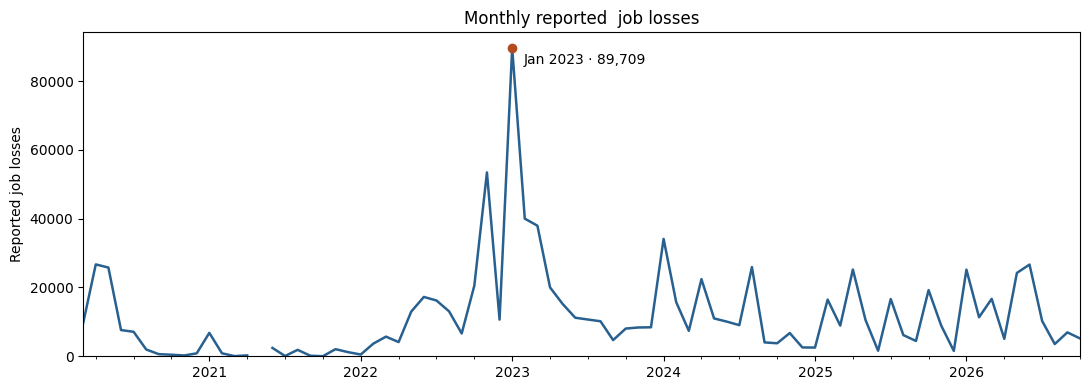

In [ ]:
import matplotlib.pyplot as plt

trend = monthly_losses.to_timestamp().asfreq("MS")
ax = trend.plot(figsize=(11, 4), color="#286090", linewidth=1.8)

peak_date = peak_month.to_timestamp()
peak_losses = monthly_losses.loc[peak_month]
ax.scatter(peak_date, peak_losses, color="#B34B20", zorder=3)
ax.annotate(
    f"{peak_date:%b %Y} · {peak_losses:,.0f}",
    xy=(peak_date, peak_losses),
    xytext=(8, -12),
    textcoords="offset points"
)

ax.set(title="Monthly reported  job losses", xlabel="", ylabel="Reported job losses")
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

In [ ]:
sectors = ["Retail", "Hardware", "Consumer"]

sector_monthly = (
    monthly_data.loc[monthly_data["Industry"].isin(sectors)]
    .groupby(["Industry", "Month"])["LayoffsForTotal"]
    .sum(min_count=1)
    .unstack("Industry")
)

sector_peaks = pd.DataFrame({
    "Peak month": sector_monthly.idxmax(),
    "Reported job losses in peak month": sector_monthly.max()
})

display(sector_peaks.loc[sectors])

,Peak month,Reported job losses in peak month
Industry,,
Retail,2026-01,16116.0
Hardware,2025-04,22000.0
Consumer,2022-11,15570.0


Across all sectors, reported job losses peaked in January 2023 at 89,709. The three named sectors with the largest losses over the full study period peaked at different times. Consumer peaked in November 2022 with 15,570 reported losses, Hardware in April 2025 with 22,000, and Retail in January 2026 with 16,116.

In [ ]:
hardware_peak = sector_peaks.loc["Hardware", "Peak month"]
hardware_records = monthly_data.loc[
    monthly_data["Industry"].eq("Hardware") & monthly_data["Month"].eq(hardware_peak)
]

by_company = (
    hardware_records.groupby("company")["LayoffsForTotal"]
    .sum(min_count=1)
    .dropna()
    .sort_values(ascending=False)
    .rename("Reported job losses")
    .to_frame()
)
by_company["Share of Hardware peak (%)"] = (
    100 * by_company["Reported job losses"] / hardware_records["LayoffsForTotal"].sum()
).round(1)

display(by_company.head(5))

,Reported job losses,Share of Hardware peak (%)
company,,
Intel,22000.0,100.0


In [ ]:
for sector in ["Retail", "Consumer"]:
    month = sector_peaks.loc[sector, "Peak month"]
    records = monthly_data.loc[
        monthly_data["Industry"].eq(sector) & monthly_data["Month"].eq(month)
    ]

    company_losses = (
        records.groupby("company")["LayoffsForTotal"]
        .sum(min_count=1)
        .dropna()
        .sort_values(ascending=False)
    )

    sector_total = records["LayoffsForTotal"].sum(min_count=1)
    top_companies = company_losses.head(5).to_frame("Reported job losses")
    top_companies["Share of sector peak (%)"] = (
        100 * top_companies["Reported job losses"] / sector_total
    ).round(1)

    print(f"{sector} | {month} | {sector_total:,.0f} reported job losses")
    display(top_companies)

Retail | 2026-01 | 16,116 reported job losses


,Reported job losses,Share of sector peak (%)
company,,
Amazon,16000.0,99.3
MercadoLibre,116.0,0.7


Consumer | 2022-11 | 15,570 reported job losses


,Reported job losses,Share of sector peak (%)
company,,
Meta,11000.0,70.6
Twitter,3700.0,23.8
Juul,400.0,2.6
Wildlife Studios,300.0,1.9
Cameo,80.0,0.5


In Retail’s January 2026 peak, Amazon accounted for 16,000 of 16,116 reported job losses (99.3%). In Hardware’s April 2025 peak, Intel accounted for all 22,000. Consumer’s November 2022 peak was shared more widely, though Meta (11,000) and Twitter (3,700) together accounted for 94.4% of its 15,570 reported losses. Each percentage refers to that sector’s reported losses during its own peak month.

### Funding-stage coverage across the full historical period

In [ ]:
stage_groups = layoffs_staged.groupby("FundingStage")["LayoffsForTotal"]

stage_summary = stage_groups.agg(
    Records="size",
    RecordsWithHeadcount="count"
)
stage_summary["ReportedJobLosses"] = stage_groups.sum(min_count=1)
stage_summary["HeadcountCoveragePct"] = (
    100 * stage_summary["RecordsWithHeadcount"] / stage_summary["Records"]
).round(1)

display(stage_summary.sort_values("ReportedJobLosses", ascending=False))

,Records,RecordsWithHeadcount,ReportedJobLosses,HeadcountCoveragePct
FundingStage,,,,
Post-IPO,1128,799,589142.0,70.8
Unknown,784,472,82530.0,60.2
Acquired,424,278,75637.0,65.6
Series B,496,315,32283.0,63.5
Series C,459,289,28769.0,63.0
Series D,369,258,28039.0,69.9
Series E,211,158,25697.0,74.9
Series F,129,98,17558.0,76.0
Private Equity,86,53,14387.0,61.6


Post-IPO companies accounted for 589,142 reported job losses, the largest total of any funding-stage category. Of their 1,128 layoff records, 799 included a headcount (70.8%). Another 82,530 reported losses came from records with an unknown funding stage, so part of the total cannot be assigned to a stage.

### Country coverage and case selection

In [ ]:
country_groups = layoffs_staged.groupby("CountryReported")["LayoffsForTotal"]

country_summary = country_groups.agg(
    Records="size",
    RecordsWithHeadcount="count"
)
country_summary["ReportedJobLosses"] = country_groups.sum(min_count=1)
country_summary["HeadcountCoveragePct"] = (
    100 * country_summary["RecordsWithHeadcount"] / country_summary["Records"]
).round(1)

display(country_summary.nlargest(10, "ReportedJobLosses"))

,Records,RecordsWithHeadcount,ReportedJobLosses,HeadcountCoveragePct
CountryReported,,,,
United States,2922,1850,664722.0,63.3
India,351,273,67889.0,77.8
Germany,136,99,32153.0,72.8
United Kingdom,159,87,23694.0,54.7
Netherlands,32,22,22375.0,68.8
Sweden,45,34,20509.0,75.6
Canada,185,136,17204.0,73.5
Israel,191,146,16349.0,76.4
Brazil,90,77,11939.0,85.6


Records tagged United States accounted for 664,722 reported job losses, followed by India (67,889) and Germany (32,153). Headcount coverage varied across the three countries: 63.3% for the United States, 77.8% for India, and 72.8% for Germany. The country label describes the layoff record. A multinational announcement can include employees in several countries.

## United States

### Retail

In [ ]:
retail_hires = pd.read_csv(
    "https://fred.stlouisfed.org/graph/fredgraph.csv?id=JTS4400HIL",
    na_values=["."]
)
retail_hires.columns = ["Month", "HiresThousands"]
retail_hires["Month"] = pd.to_datetime(retail_hires["Month"]).dt.to_period("M")
retail_hires["RetailHires"] = retail_hires["HiresThousands"] * 1_000

# Inspect observations within the period covered by the layoff data.
retail_hires = retail_hires.loc[
    retail_hires["Month"].between(monthly_losses.index.min(), monthly_losses.index.max())
].dropna(subset=["RetailHires"]).sort_values("Month")

print("First and last hiring months:", retail_hires["Month"].min(), retail_hires["Month"].max())
display(retail_hires[["Month", "RetailHires"]].tail(6))

First and last hiring months: 2020-03 2026-09


,Month,RetailHires
304,2026-04,632000
305,2026-05,658000
306,2026-06,646000
307,2026-07,663000
308,2026-08,664000
309,2026-09,704000


**Hiring data source and scope**

 I use monthly U.S. retail hiring as a benchmark because Retail had the most reported job losses among named sectors in our dataset, and the United States was the most frequently recorded country. The hiring estimates come from the U.S. Bureau of Labor Statistics’ Job Openings and Labor Turnover Survey (JOLTS), accessed through FRED. The series is seasonally adjusted and published in thousands, so we multiplied each value by 1,000. The two datasets overlap from March 2020 through September 2026. FRED source — Hires: Retail Trade, JTS4400HIL

In this extract, estimated U.S. retail hires rose from 632,000 in April 2026 to 704,000 in September 2026, an increase of 72,000 (11.4%). This describes hiring across the broader U.S. retail market. Determining when Amazon or another tracked employer increased hiring would require monthly hiring data for that company

In [ ]:
# Find the U.S.-tagged Retail layoff peak within the hiring data's date range.
hires = retail_hires.set_index("Month")["RetailHires"].sort_index()

us_retail = monthly_data.loc[
    monthly_data["CountryReported"].eq("United States")
    & monthly_data["Industry"].eq("Retail")
    & monthly_data["Month"].isin(hires.index)
]
monthly_cuts = us_retail.groupby("Month")["LayoffsForTotal"].sum(min_count=1)
peak = monthly_cuts.idxmax()

# Use the three calendar months immediately before the peak as the baseline.
baseline_months = pd.period_range(peak - 3, peak - 1, freq="M")
before = hires.reindex(baseline_months)
assert before.notna().all(), "Check the hiring data for a missing baseline month."
baseline = before.mean()

print(f"U.S.-tagged Retail layoff peak: {peak} ({monthly_cuts.loc[peak]:,.0f} reported losses)")
print(f"Average monthly hires, {peak - 3} to {peak - 1}: {baseline:,.0f}")

# Show hiring in the peak month and every available month afterward.
comparison = hires.loc[peak:].to_frame("USRetailHires")
comparison["PercentFromBaseline"] = (
    100 * (comparison["USRetailHires"] / baseline - 1)
).round(1)
display(comparison)

U.S.-tagged Retail layoff peak: 2026-01 (16,000 reported losses)
Average monthly hires, 2025-10 to 2025-12: 560,000


,USRetailHires,PercentFromBaseline
Month,,
2026-01,582000,3.9
2026-02,611000,9.1
2026-03,680000,21.4
2026-04,632000,12.9
2026-05,658000,17.5
2026-06,646000,15.4
2026-07,663000,18.4
2026-08,664000,18.6
2026-09,704000,25.7


U.S. retail hiring around the January 2026 layoff peak. The tracker recorded 16,000 reported job losses in U.S.-tagged Retail announcements in January 2026. That same month, the broader U.S. retail industry recorded an estimated 582,000 hires, 3.9% above its October–December 2025 average of 560,000. Hiring fluctuated over the following eight months but stayed above that baseline, reaching 704,000 in September, 25.7% above the baseline. These figures describe hiring across U.S. retail. Determining whether the employers that announced cuts resumed hiring would require company-level data.

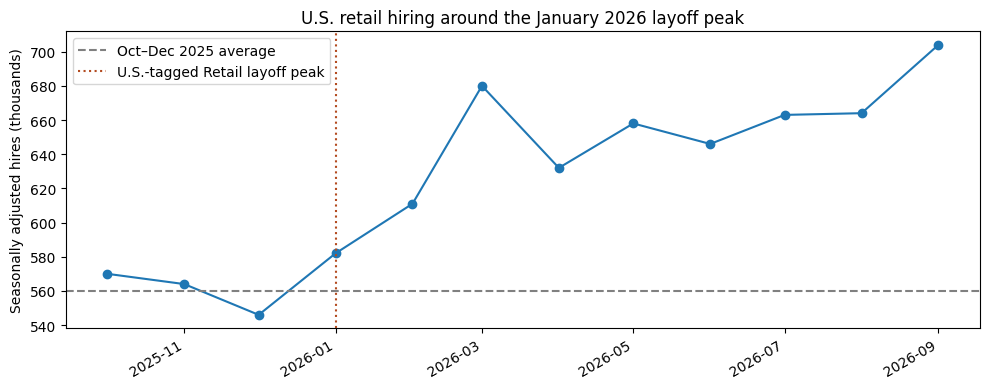

In [ ]:
chart_hires = hires.loc[peak - 3:].sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(chart_hires.index.to_timestamp(), chart_hires / 1_000, marker="o")
ax.axhline(
    baseline / 1_000, color="gray", linestyle="--",
    label="Oct–Dec 2025 average"
)
ax.axvline(
    peak.to_timestamp(), color="#B34B20", linestyle=":",
    label="U.S.-tagged Retail layoff peak"
)
ax.set(
    title="U.S. retail hiring around the January 2026 layoff peak",
    ylabel="Seasonally adjusted hires (thousands)",
    xlabel=""
)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Hardware

We compare reported layoffs at U.S.-tagged Hardware companies with monthly hiring across U.S. durable goods manufacturers. This provides broader labor-market context for the Hardware layoff peak.

Source: U.S. Bureau of Labor Statistics, JOLTS, via FRED. Series JTS3200HIL.

In [ ]:
durable_hires = pd.read_csv(
    "https://fred.stlouisfed.org/graph/fredgraph.csv?id=JTS3200HIL",
    na_values=["."]
)
durable_hires.columns = ["Month", "HiresThousands"]
durable_hires["Month"] = pd.to_datetime(durable_hires["Month"]).dt.to_period("M")
durable_hires["DurableGoodsHires"] = durable_hires["HiresThousands"] * 1_000

# Use months covered by both hiring case studies.
durable_hires = durable_hires.loc[
    durable_hires["Month"].isin(retail_hires["Month"])
].dropna(subset=["DurableGoodsHires"]).sort_values("Month")

us_hardware = monthly_data.loc[
    monthly_data["CountryReported"].eq("United States")
    & monthly_data["Industry"].eq("Hardware")
    & monthly_data["Month"].isin(durable_hires["Month"])
]
hardware_cuts = us_hardware.groupby("Month")["LayoffsForTotal"].sum(min_count=1)
us_hardware_peak = hardware_cuts.idxmax()

print("Hiring coverage:", durable_hires["Month"].min(), "to", durable_hires["Month"].max())
print("U.S.-tagged Hardware peak:", us_hardware_peak)
print(f"Reported losses in peak month: {hardware_cuts.loc[us_hardware_peak]:,.0f}")

Hiring coverage: 2020-03 to 2026-09
U.S.-tagged Hardware peak: 2025-04
Reported losses in peak month: 22,000


In [ ]:
durable_monthly = durable_hires.set_index("Month")["DurableGoodsHires"].sort_index()

baseline_months = pd.period_range(us_hardware_peak - 3, us_hardware_peak - 1, freq="M")
before_peak = durable_monthly.reindex(baseline_months)
assert before_peak.notna().all(), "A baseline month is missing."
hardware_baseline = before_peak.mean()

hardware_comparison = durable_monthly.loc[us_hardware_peak:].to_frame()
hardware_comparison["DifferenceInHires"] = (
    hardware_comparison["DurableGoodsHires"] - hardware_baseline
).round()
hardware_comparison["PercentFromBaseline"] = (
    100 * (hardware_comparison["DurableGoodsHires"] / hardware_baseline - 1)
).round(1)

print(f"Jan–Mar 2025 average monthly hires: {hardware_baseline:,.0f}")
display(hardware_comparison)

Jan–Mar 2025 average monthly hires: 183,333


,DurableGoodsHires,DifferenceInHires,PercentFromBaseline
Month,,,
2025-04,185000,1667.0,0.9
2025-05,164000,-19333.0,-10.5
2025-06,171000,-12333.0,-6.7
2025-07,167000,-16333.0,-8.9
2025-08,165000,-18333.0,-10.0
2025-09,172000,-11333.0,-6.2
2025-10,171000,-12333.0,-6.7
2025-11,157000,-26333.0,-14.4
2025-12,154000,-29333.0,-16.0


Hiring around the U.S.-tagged Hardware layoff peak. In April 2025, the tracker recorded 22,000 Hardware job losses, all attributed to Intel. That month, U.S. durable goods manufacturers recorded 185,000 hires, slightly above their January–March average of about 183,333. Hiring fell to 164,000 in May 2025 and stayed below that average through May 2026. In June 2026, hiring reached 208,000, or 13.5% above the baseline. This was the first return above baseline after the dip. The figures describe hiring across U.S. durable goods manufacturing. Intel’s own hiring trajectory would require company-level data.

### Consumer

In [ ]:
us_consumer = monthly_data.loc[
    monthly_data["CountryReported"].eq("United States")
    & monthly_data["Industry"].eq("Consumer")
]

consumer_monthly = (
    us_consumer.groupby("Month")["LayoffsForTotal"]
    .sum(min_count=1)
    .dropna()
)

consumer_peak = consumer_monthly.idxmax()
peak_total = consumer_monthly.loc[consumer_peak]

companies = (
    us_consumer.loc[us_consumer["Month"].eq(consumer_peak)]
    .groupby("company")["LayoffsForTotal"]
    .sum(min_count=1)
    .dropna()
    .sort_values(ascending=False)
    .rename("Reported job losses")
    .to_frame()
)
companies["Share of peak (%)"] = (
    100 * companies["Reported job losses"] / peak_total
).round(1)

print(f"U.S.-tagged Consumer peak: {consumer_peak}")
print(f"Reported job losses: {peak_total:,.0f}")
display(companies.head(5))

U.S.-tagged Consumer peak: 2022-11
Reported job losses: 15,215


,Reported job losses,Share of peak (%)
company,,
Meta,11000.0,72.3
Twitter,3700.0,24.3
Juul,400.0,2.6
Cameo,80.0,0.5
Kabam,35.0,0.2


November 2022 was the peak month for reported layoffs among U.S.-tagged Consumer companies in the dataset. Of the 15,215 reported job losses, 11,000 came from Meta and 3,700 from Twitter. Together, these two social media companies accounted for 14,700 losses, or 96.6% of the monthly total

In [ ]:
info_series = "JTU5100HIL"
info_hires = pd.read_csv(
    f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={info_series}",
    na_values=["."]
)

info_hires.columns = ["Month", "HiresThousands"]
info_hires["Month"] = pd.to_datetime(info_hires["Month"]).dt.to_period("M")
monthly_hires = info_hires.set_index("Month")["HiresThousands"] * 1_000

# Compare the peak month and the following six months with one year earlier.
months = pd.period_range(start=consumer_peak, periods=7, freq="M")
consumer_comparison = monthly_hires.reindex(months).to_frame("USInformationHires")
consumer_comparison.index.name = "Month"
consumer_comparison["HiresOneYearEarlier"] = monthly_hires.reindex(months - 12).to_numpy()
consumer_comparison["YearOverYearPct"] = (
    100 * (consumer_comparison["USInformationHires"]
           / consumer_comparison["HiresOneYearEarlier"] - 1)
).round(1)

display(consumer_comparison)

,USInformationHires,HiresOneYearEarlier,YearOverYearPct
Month,,,
2022-11,101000,104000,-2.9
2022-12,53000,73000,-27.4
2023-01,76000,138000,-44.9
2023-02,75000,68000,10.3
2023-03,94000,96000,-2.1
2023-04,78000,108000,-27.8
2023-05,69000,115000,-40.0


After the November 2022 peak in U.S.-tagged Consumer layoffs, U.S. Information employers recorded fewer hires than a year earlier in five of the next six months. January had the largest shortfall, with 76,000 hires compared with 138,000 in January 2022, a 44.9% decline. February was the exception, with hiring 10.3% above the previous February. This benchmark describes the broader U.S. Information industry. Determining when Meta or Twitter resumed hiring would require company-level data

## India

In [ ]:
india = layoffs_staged.loc[layoffs_staged["CountryReported"].eq("India")]

india_sectors = (
    india.groupby("Industry")["LayoffsForTotal"]
    .agg(
        ReportedJobLosses=lambda counts: counts.sum(min_count=1),
        Records="size",
        RecordsWithCount="count",
    )
    .sort_values("ReportedJobLosses", ascending=False)
)

india_total = india["LayoffsForTotal"].sum()
india_sectors["ShareOfIndiaLossesPct"] = (
    100 * india_sectors["ReportedJobLosses"] / india_total
).round(1)
india_sectors["RecordsWithCountPct"] = (
    100 * india_sectors["RecordsWithCount"] / india_sectors["Records"]
).round(1)

print(f"India-tagged reported job losses: {india_total:,.0f}")
display(india_sectors.head(5))

India-tagged reported job losses: 67,889


,ReportedJobLosses,Records,RecordsWithCount,ShareOfIndiaLossesPct,RecordsWithCountPct
Industry,,,,,
Education,14474.0,53,41,21.3,77.4
Finance,10241.0,48,40,15.1,83.3
Food,8437.0,39,28,12.4,71.8
Consumer,7348.0,29,25,10.8,86.2
Transportation,7170.0,24,20,10.6,83.3


Education led India-tagged records with 14,474 reported job losses (21.3%), followed by Finance with 10,241 (15.1%) and Food with 8,437 (12.4%). Together, these sectors accounted for 33,152 of 67,889 reported losses, or 48.8%. The totals cover records that disclosed a layoff count. In Education, 41 of 53 records included one.

In [ ]:
india_top_sectors = india_sectors.head(3).index

india_monthly = monthly_data.loc[
    monthly_data["CountryReported"].eq("India")
    & monthly_data["Industry"].isin(india_top_sectors)
]

monthly_totals = (
    india_monthly.groupby(["Industry", "Month"])["LayoffsForTotal"]
    .sum(min_count=1)
    .dropna()
    .rename("ReportedJobLosses")
    .reset_index()
)

peak_counts = monthly_totals.groupby("Industry")["ReportedJobLosses"].transform("max")
india_peaks = monthly_totals.loc[monthly_totals["ReportedJobLosses"].eq(peak_counts)]
display(india_peaks.set_index("Industry").loc[india_top_sectors])

,Month,ReportedJobLosses
Industry,,
Education,2022-10,2630.0
Finance,2024-06,3530.0
Food,2020-05,1620.0


Among India-tagged records, Education had the highest total across the study period (14,474 reported job losses) and peaked in October 2022 at 2,630. Finance recorded the largest monthly spike of the three sectors, with 3,530 reported losses in June 2024. Food peaked earlier, in May 2020, with 1,620. Food’s peak therefore belongs to the early pandemic period and should be labeled that way in the analysis.

### Education

In [ ]:
education_month = india_peaks.loc[
    india_peaks["Industry"].eq("Education"), "Month"
].item()

education_records = india_monthly.loc[
    india_monthly["Industry"].eq("Education")
    & india_monthly["Month"].eq(education_month)
]

education_companies = (
    education_records.groupby("company")["LayoffsForTotal"]
    .sum(min_count=1)
    .dropna()
    .sort_values(ascending=False)
    .rename("ReportedJobLosses")
    .to_frame()
)

education_total = education_records["LayoffsForTotal"].sum()
education_companies["ShareOfPeakPct"] = (
    100 * education_companies["ReportedJobLosses"] / education_total
).round(1)

print(f"India-tagged Education | {education_month} | {education_total:,.0f} reported losses")
display(education_companies)

India-tagged Education | 2022-10 | 2,630 reported losses


,ReportedJobLosses,ShareOfPeakPct
company,,
Byju's,2500.0,95.1
FrontRow,130.0,4.9


India-tagged Education layoffs peaked in October 2022 at 2,630 reported job losses. Byju’s accounted for 2,500 (95.1%) and FrontRow for 130 (4.9%). One company therefore accounted for nearly the entire recorded peak.

In [ ]:
# Source: Naukri JobSpeak, July 2023, Annexure Industry Data
# https://www.infoedge.in/pdfs/News_Events_pdfs/Naukri-Jobspeak-July-2023.pdf
# Industry row: Education/Teaching/Training

india_education_demand = pd.DataFrame({
    "Month": pd.period_range("2022-07", "2023-04", freq="M"),
    "JobSpeakIndex": [5311, 5040, 5448, 4761, 5346,
                      5208, 5076, 5221, 5638, 5005]
}).set_index("Month")

index_values = india_education_demand["JobSpeakIndex"]
education_baseline = index_values.loc["2022-07":"2022-09"].mean()

india_education_demand["PctFromBaseline"] = (
    100 * (index_values / education_baseline - 1)
).round(1)

print(f"July–September 2022 average: {education_baseline:,.1f} index points")
display(india_education_demand)

July–September 2022 average: 5,266.3 index points


,JobSpeakIndex,PctFromBaseline
Month,,
2022-07,5311,0.8
2022-08,5040,-4.3
2022-09,5448,3.4
2022-10,4761,-9.6
2022-11,5346,1.5
2022-12,5208,-1.1
2023-01,5076,-3.6
2023-02,5221,-0.9
2023-03,5638,7.1


In October 2022, the peak month for reported India-tagged Education layoffs, Naukri’s Education/Teaching/Training index was 9.6% below its July–September average of 5,266.3 points. Over the following six months, hiring demand exceeded that average only in November (+1.5%) and March (+7.1%). By April 2023, it was 5.0% below baseline. The index tracks recruitment activity across the broader education sector. Determining when Byju’s resumed hiring would require company-level data. Source: Naukri JobSpeak, July 2023, industry annexure

### Finance

In [ ]:
finance_month = india_peaks.loc[
    india_peaks["Industry"].eq("Finance"), "Month"
].item()

finance_records = india_monthly.loc[
    india_monthly["Industry"].eq("Finance")
    & india_monthly["Month"].eq(finance_month)
]

finance_companies = (
    finance_records.groupby("company")["LayoffsForTotal"]
    .sum(min_count=1)
    .dropna()
    .sort_values(ascending=False)
    .rename("ReportedJobLosses")
    .to_frame()
)

finance_total = finance_records["LayoffsForTotal"].sum()
finance_companies["ShareOfPeakPct"] = (
    100 * finance_companies["ReportedJobLosses"] / finance_total
).round(1)

print(f"India-tagged Finance | {finance_month} | {finance_total:,.0f} reported losses")
display(finance_companies)

India-tagged Finance | 2024-06 | 3,530 reported losses


,ReportedJobLosses,ShareOfPeakPct
company,,
Paytm,3500.0,99.2
Simpl,30.0,0.8


In [ ]:
# Source: Naukri JobSpeak, March 2025, Annexure Industry Data
# Industry row: Banking / Financial Services / Broking
# https://www.scribd.com/document/878209043/Naukri-Jobspeak-March-2025

india_finance_demand = pd.DataFrame({
    "Month": pd.period_range("2024-03", "2024-12", freq="M"),
    "JobSpeakIndex": [3858, 3890, 4214, 3705, 4152,
                      3678, 3917, 3915, 3412, 3770]
}).set_index("Month")

finance_index = india_finance_demand["JobSpeakIndex"]
finance_baseline = finance_index.loc["2024-03":"2024-05"].mean()

india_finance_demand["PctFromBaseline"] = (
    100 * (finance_index / finance_baseline - 1)
).round(1)

print(f"March–May 2024 average: {finance_baseline:,.1f} index points")
display(india_finance_demand)

March–May 2024 average: 3,987.3 index points


,JobSpeakIndex,PctFromBaseline
Month,,
2024-03,3858,-3.2
2024-04,3890,-2.4
2024-05,4214,5.7
2024-06,3705,-7.1
2024-07,4152,4.1
2024-08,3678,-7.8
2024-09,3917,-1.8
2024-10,3915,-1.8
2024-11,3412,-14.4


In June 2024, when India-tagged Finance layoffs peaked, Naukri’s Banking / Financial Services / Broking index was 7.1% below its March–May average of 3,987.3 points. The index rose to 4.1% above baseline in July, then stayed below baseline from August through December. November had the largest shortfall at 14.4%. These figures describe recruitment demand across the broader financial sector. Determining when Paytm resumed hiring would require company-level data.

### Food

In [ ]:
food_month = india_peaks.loc[
    india_peaks["Industry"].eq("Food"), "Month"
].item()

food_records = india_monthly.loc[
    india_monthly["Industry"].eq("Food")
    & india_monthly["Month"].eq(food_month)
]

food_companies = (
    food_records.groupby("company")["LayoffsForTotal"]
    .sum(min_count=1)
    .dropna()
    .sort_values(ascending=False)
    .rename("ReportedJobLosses")
    .to_frame()
)

food_total = food_records["LayoffsForTotal"].sum()
food_companies["ShareOfPeakPct"] = (
    100 * food_companies["ReportedJobLosses"] / food_total
).round(1)

print(f"India-tagged Food | {food_month} | {food_total:,.0f} reported losses")
display(food_companies)

India-tagged Food | 2020-05 | 1,620 reported losses


,ReportedJobLosses,ShareOfPeakPct
company,,
Swiggy,1100.0,67.9
Zomato,520.0,32.1


India Food — hiring demand after the May 2020 layoffs. Swiggy and Zomato accounted for all 1,620 reported job losses in India-tagged Food records that May. Vahan observed an increase in demand from food-delivery and e-commerce employers around late September. By November, it reported that demand for food and grocery delivery workers had returned to pre-COVID levels. This tracks demand for delivery workers across the market. It leaves open how many employees either company hired after the layoffs.

Source: Vahan findings reported by *The Financial Express*, 22 November 2020.

## Germany

In [ ]:
germany = layoffs_staged.loc[layoffs_staged["CountryReported"].eq("Germany")]

germany_sectors = (
    germany.groupby("Industry")["LayoffsForTotal"]
    .agg(
        ReportedJobLosses=lambda counts: counts.sum(min_count=1),
        Records="size",
        RecordsWithCount="count",
    )
    .sort_values("ReportedJobLosses", ascending=False)
)

germany_total = germany["LayoffsForTotal"].sum()
germany_sectors["ShareOfGermanyLossesPct"] = (
    100 * germany_sectors["ReportedJobLosses"] / germany_total
).round(1)
germany_sectors["RecordsWithCountPct"] = (
    100 * germany_sectors["RecordsWithCount"] / germany_sectors["Records"]
).round(1)

print(f"Germany-tagged reported job losses: {germany_total:,.0f}")
display(germany_sectors.head(5))

Germany-tagged reported job losses: 32,153


,ReportedJobLosses,Records,RecordsWithCount,ShareOfGermanyLossesPct,RecordsWithCountPct
Industry,,,,,
Other,12207.0,15,12,38.0,80.0
Food,9878.0,14,11,30.7,78.6
Retail,1904.0,18,12,5.9,66.7
Manufacturing,1498.0,2,2,4.7,100.0
Aerospace,1000.0,1,1,3.1,100.0


Of 32,153 reported job losses in Germany-tagged records, 12,207 (38.0%) fell under “Other,” the largest category. Among named sectors, Food led with 9,878 (30.7%), followed by Retail with 1,904 (5.9%) and Manufacturing with 1,498 (4.7%). Both Manufacturing records included a job-loss count, but that sector’s total comes from just two records.

In [ ]:
germany_top_sectors = germany_sectors.drop(
    index=["Other", "Unknown"], errors="ignore"
).head(3).index

germany_monthly = monthly_data.loc[
    monthly_data["CountryReported"].eq("Germany")
    & monthly_data["Industry"].isin(germany_top_sectors)
]

germany_monthly_totals = (
    germany_monthly.groupby(["Industry", "Month"])["LayoffsForTotal"]
    .sum(min_count=1)
    .dropna()
    .rename("ReportedJobLosses")
    .reset_index()
)

peak_by_sector = germany_monthly_totals.groupby("Industry")["ReportedJobLosses"].transform("max")
germany_peaks = germany_monthly_totals.loc[
    germany_monthly_totals["ReportedJobLosses"].eq(peak_by_sector)
]

display(germany_peaks.set_index("Industry").loc[germany_top_sectors])

,Month,ReportedJobLosses
Industry,,
Food,2023-04,8000.0
Retail,2025-01,840.0
Manufacturing,2024-08,1400.0


Germany’s total includes 12,207 reported job losses classified as “Other” (38.0% of 32,153). The label gives too little industry detail to choose a reliable hiring benchmark. For the hiring case studies, we therefore selected the three named sectors with the most reported losses: Food, Retail, and Manufacturing. All sector shares use the full Germany-tagged total.

In [ ]:
# Select each sector's records for its own peak month.
germany_peak_records = germany_monthly.merge(
    germany_peaks[["Industry", "Month", "ReportedJobLosses"]].rename(
        columns={"ReportedJobLosses": "SectorPeakTotal"}
    ),
    on=["Industry", "Month"],
    how="inner",
    validate="many_to_one",
)

germany_peak_companies = (
    germany_peak_records
    .groupby(["Industry", "Month", "SectorPeakTotal", "company"])["LayoffsForTotal"]
    .sum(min_count=1)
    .dropna()
    .rename("CompanyReportedLosses")
    .reset_index()
)

germany_peak_companies["ShareOfSectorPeakPct"] = (
    100 * germany_peak_companies["CompanyReportedLosses"]
    / germany_peak_companies["SectorPeakTotal"]
).round(1)

display(
    germany_peak_companies.sort_values(
        ["Industry", "CompanyReportedLosses"], ascending=[True, False]
    )
)

,Industry,Month,SectorPeakTotal,company,CompanyReportedLosses,ShareOfSectorPeakPct
0,Food,2023-04,8000.0,Flink,8000.0,100.0
1,Manufacturing,2024-08,1400.0,Infineon,1400.0,100.0
3,Retail,2025-01,840.0,Wayfair,730.0,86.9
2,Retail,2025-01,840.0,Chrono24,110.0,13.1


In the Germany-tagged records, Flink accounted for all 8,000 reported Food losses in April 2023, and Infineon accounted for all 1,400 reported Manufacturing losses in August 2024. Two companies contributed to the January 2025 Retail peak of 840: Wayfair accounted for 730 (86.9%) and Chrono24 for 110 (13.1%). Each percentage is the company’s share of reported losses in that sector’s peak month.

### Food

In [ ]:
germany_food_month = germany_peaks.loc[
    germany_peaks["Industry"].eq("Food"), "Month"
].item()

germany_food_records = germany_monthly.loc[
    germany_monthly["Industry"].eq("Food")
    & germany_monthly["Month"].eq(germany_food_month)
]

company_losses = (
    germany_food_records.groupby("company")["LayoffsForTotal"]
    .sum(min_count=1)
    .dropna()
    .sort_values(ascending=False)
)

germany_food_total = company_losses.sum()
germany_food_companies = company_losses.rename("ReportedJobLosses").to_frame()
germany_food_companies["ShareOfPeakPct"] = (
    100 * company_losses / germany_food_total
).round(1)

print(f"Germany-tagged Food | {germany_food_month} | {germany_food_total:,.0f} reported losses")
display(germany_food_companies)
display(germany_food_records[["company", "LayoffsForTotal", "source"]])

Germany-tagged Food | 2023-04 | 8,000 reported losses


,ReportedJobLosses,ShareOfPeakPct
company,,
Flink,8000.0,100.0


,company,LayoffsForTotal,source
2080,Flink,8000.0,https://www.manager-magazin.de/unternehmen/tec...


Flink accounted for 8,000 reported job losses, or 81.0% of all losses in Germany-tagged Food records across the study period. The figure became public in April 2023 and covered operations across multiple countries. We therefore use April as the reporting month and interpret German hiring data as context for one of Flink’s affected markets.

#### Retail postings around the Flink announcement

The U.S. case studies use monthly estimates of how many people employers hired. For the Flink case, we could not verify a comparable monthly count of hires by German grocery-delivery employers around April 2023. We therefore use Indeed’s index of new postings for retail jobs in Germany to track how actively employers advertised roles before and after Flink’s announcement. A rise in the index indicates stronger recruiting demand. Establishing how many people started work, or when Flink resumed hiring, would require additional data. Flink’s reported cuts also spanned several countries, so the German series provides context for one affected market. Source: Indeed Hiring Lab

In [ ]:
import pandas as pd

source_de = 'https://raw.githubusercontent.com/hiring-lab/job_postings_tracker/master/DE/job_postings_by_sector_DE.csv'
de_postings = pd.read_csv(source_de, parse_dates=['date'])
de_new = de_postings.loc[de_postings['jobcountry'].eq('DE') & de_postings['variable'].eq('new postings')].copy()

In [ ]:
def germany_demand(category, peak_month):
    peak = pd.Period(peak_month, freq='M')
    months = pd.period_range(peak - 3, peak + 6, freq='M')
    daily = de_new.loc[de_new['display_name'].eq(category)].set_index('date')['indeed_job_postings_index']
    assert daily.index.is_unique, 'Duplicate daily observations'
    monthly = daily.groupby(daily.index.to_period('M')).agg(['mean', 'count']).reindex(months)
    assert monthly['count'].eq(months.days_in_month).all(), 'Incomplete daily coverage in the comparison window'
    baseline = monthly['mean'].iloc[:3].mean()
    monthly['Change from baseline (%)'] = 100 * (monthly['mean'] / baseline - 1)
    monthly.index.name = 'Month'
    print(f'{category} | Pre-peak three-month average: {baseline:.2f} index points')
    return monthly.rename(columns={'mean': 'New postings index', 'count': 'Days observed'}).round(1)

germany_food_context = germany_demand('Retail', '2023-04')
print(germany_food_context.to_string())

Retail | Pre-peak three-month average: 185.65 index points
         New postings index  Days observed  Change from baseline (%)
Month                                                               
2023-01               183.9             31                      -0.9
2023-02               177.8             28                      -4.2
2023-03               195.2             31                       5.2
2023-04               206.1             30                      11.0
2023-05               200.1             31                       7.8
2023-06               199.7             30                       7.6
2023-07               226.0             31                      21.8
2023-08               252.8             31                      36.2
2023-09               242.7             30                      30.7
2023-10               249.9             31                      34.6


In April 2023, German retail job postings were 11.0% above their January–March average. The index stayed above that average for the next six months and ended October 34.6% higher. Grocery delivery is only part of retail. These figures describe advertised demand in a related market while Flink was reporting cuts across several countries.

### Retail

Wayfair accounted for 730 of the 840 reported losses in Germany-tagged Retail records and Chrono24 accounted for 110. We compare the German Retail new postings index with its October–December 2024 average.

In [ ]:
germany_retail_demand = germany_demand('Retail', '2025-01')
print(germany_retail_demand.to_string())

Retail | Pre-peak three-month average: 151.68 index points
         New postings index  Days observed  Change from baseline (%)
Month                                                               
2024-10               168.4             31                      11.0
2024-11               142.2             30                      -6.2
2024-12               144.4             31                      -4.8
2025-01               185.2             31                      22.1
2025-02               156.7             28                       3.3
2025-03               151.5             31                      -0.1
2025-04               167.6             30                      10.5
2025-05               153.6             31                       1.3
2025-06               134.3             30                     -11.5
2025-07               141.8             31                      -6.5


In January 2025, German Retail new job postings were 22.1% above the preceding three-month average. The increase did not persist. By June the index was 11.5% below baseline, and in July it was 6.5% below. The sector index gives recruiting context for the layoff peak. Tracking hires at Wayfair or Chrono24 would require employer-level data.

### Manufacturing

Infineon accounted for all 1,400 reported losses in the Germany-tagged Manufacturing peak. We use Indeed’s Production & Manufacturing occupational category as a broad indicator of recruiting demand and compare it with May–July 2024.

In [ ]:
germany_manufacturing_demand = germany_demand('Production & Manufacturing', '2024-08')
print(germany_manufacturing_demand.to_string())

Production & Manufacturing | Pre-peak three-month average: 172.34 index points
         New postings index  Days observed  Change from baseline (%)
Month                                                               
2024-05               170.4             31                      -1.1
2024-06               180.4             30                       4.7
2024-07               166.1             31                      -3.6
2024-08               167.7             31                      -2.7
2024-09               174.9             30                       1.5
2024-10               153.0             31                     -11.2
2024-11               148.0             30                     -14.1
2024-12               140.2             31                     -18.7
2025-01               137.5             31                     -20.2
2025-02               146.8             28                     -14.8


German Production & Manufacturing postings were 2.7% below baseline in August 2024. September briefly exceeded baseline by 1.5%, then postings stayed below it from October through February. January had the largest shortfall at 20.2%. This measures advertised production and manufacturing roles across employers. Infineon’s own hiring and the geographic distribution of its cuts require separate evidence.

## Hiring and recruitment around nine layoff peaks

Each outcome describes the market indicator for that case. Company rehiring and worker re-employment would require employer or individual records.

| Country | Sector and layoff peak | Indicator and benchmark | Observed outcome |
|---|---|---|---|
| U.S. | Retail · Jan 2026 | Retail hires vs. prior three-month average | Above baseline at the peak and through Sep 2026. |
| U.S. | Hardware · Apr 2025 | Durable-goods hires vs. prior three-month average | Below from May 2025 through May 2026. First return above in Jun 2026, 14 months after the peak. |
| U.S. | Consumer · Nov 2022 | Information hires vs. same month one year earlier | First above in Feb 2023, three months after the peak. Below again Mar–May. |
| India | Education · Oct 2022 | Education JobSpeak index vs. prior three-month average | Above one month later in Nov, then below in Dec. |
| India | Finance · Jun 2024 | Banking and financial services JobSpeak index vs. prior three-month average | Above one month later in Jul, then below from Aug through Dec. |
| India | Food · May 2020 | Delivery-worker demand vs. pre-COVID conditions | Back at pre-COVID levels by the November report. The first month of return is unknown. |
| Germany | Food · Apr 2023 | Retail new-postings index vs. prior three-month average | Above baseline in the peak month and all six follow-up months. |
| Germany | Retail · Jan 2025 | Retail new-postings index vs. prior three-month average | Above baseline in Jan, below by Jun and still below in Jul. |
| Germany | Manufacturing · Aug 2024 | Production & Manufacturing new-postings index vs. prior three-month average | Above one month later in Sep, then below from Oct through Feb. |

## How do reported layoffs vary by funding stage?

In [ ]:
stage_losses = post_emergency.groupby("FundingStage")["LayoffsForTotal"]

funding_stage_summary = stage_losses.agg(
    Records="size",
    RecordsWithCount="count",
    ReportedJobLosses=lambda counts: counts.sum(min_count=1),
    MedianLossesPerCountedRecord="median",
)

funding_stage_summary["CountCoveragePct"] = (
    100 * funding_stage_summary["RecordsWithCount"]
    / funding_stage_summary["Records"]
)

display(
    funding_stage_summary
    .sort_values("ReportedJobLosses", ascending=False)
    .round(1)
)

,Records,RecordsWithCount,ReportedJobLosses,MedianLossesPerCountedRecord,CountCoveragePct
FundingStage,,,,,
Post-IPO,623,427,338249.0,200.0,68.5
Unknown,336,192,38621.0,80.0,57.1
Acquired,212,131,34623.0,100.0,61.8
Series E,75,58,11884.0,89.0,77.3
Series C,127,70,7578.0,66.5,55.1
Series D,118,71,7368.0,80.0,60.2
Series B,152,82,7090.0,59.0,53.9
Series F,57,41,6542.0,100.0,71.9
Private Equity,41,24,6120.0,136.0,58.5


### Post-IPO companies accounted for the most reported job losses

From June 1, 2023 through October 29, 2026, Post-IPO companies accounted for 338,249 reported job losses, the highest total across funding stages. Of 623 Post-IPO records, 427 included a job-loss count (68.5%). Among those records, the median was 200 jobs lost.

Series J had the highest median at 300 jobs lost, but that figure came from only four records. Coverage also varied by stage. For example, only 10 of 82 Seed records included a count (12.2%), which limits comparisons of total losses.

These figures describe how reported layoffs varied by funding stage. Measuring how soon layoffs followed a funding round would require the date of each company’s preceding round.

## Findings across the United States, India and Germany

Reported layoff peaks often reflected decisions by a small number of employers. Amazon accounted for all 16,000 reported losses in the U.S.-tagged Retail peak, Paytm accounted for 99.2% of India’s Finance peak, and Wayfair accounted for 86.9% of Germany’s Retail peak. Country tags identify how the tracker classifies an announcement. A multinational announcement can include workers in several countries.

**Retail across two countries.** U.S. retail hires stayed above the preceding three-month average from the January 2026 layoff peak through September. In Germany, the retail postings index rose above baseline in January 2025 and fell below it by June. These cases show how a large employer can announce cuts while other employers continue recruiting. The peaks occurred a year apart, and hires and job advertisements measure different stages of recruitment.

**Food across two countries.** Swiggy and Zomato accounted for India’s May 2020 peak. A November report provides a checkpoint for delivery-worker demand. For Germany’s April 2023 Flink case, retail postings stayed above baseline throughout the following six months. The sources cover different workers and time windows, so a comparison of company rehiring speeds would require additional data.

**How to interpret the tracker.** Of 4,641 retained layoff records, 3,024 had a usable job-loss count. Rankings describe reported losses among covered records. U.S. hiring estimates, India’s recruitment indicators and Germany’s postings indices each describe their own market. The comparisons show what happened around the recorded peaks. Establishing whether layoffs caused a change, or whether displaced workers found new jobs, would require additional evidence.

## Conclusion

Hardware recorded the most reported losses after the emergency cutoff. In the longer historical window, Retail led the named industries. Only 41 of 62 post-emergency Hardware records supplied counts, so the ranking reflects quantified losses.

Sector recruitment followed different paths. German manufacturing postings crossed their benchmark one month after the peak and fell below it again. U.S. durable-goods hires took 14 months from the peak to return above baseline after a dip. Different indicators, benchmarks and observation windows limit comparisons across countries.

Post-IPO companies recorded the largest total losses. Series J had the largest median among counted records, based on four observations. Testing when layoffs occurred relative to funding rounds would require dated funding histories.

## Optional CSV exports

Run these cells to save the audit and case tables in the working directory. In Colab, use the Files panel to download them.

In [ ]:
# Export all flagged records with their full source links.
duplicate_review = (
    layoffs_clean.loc[review_mask]
    .sort_values(["company", "date", "location"])
    .rename_axis("OriginalRow")
    .reset_index()
)

review_filename = "layoff_records_for_review.csv"
duplicate_review.to_csv(review_filename, index=False)

print(f"Exported {len(duplicate_review)} rows for review.")

Exported 44 rows for review.


In [ ]:
filename = "us_retail_hires_JTS4400HIL_2026-11-09.csv"
retail_hires[["Month", "HiresThousands", "RetailHires"]].to_csv(filename, index=False)

In [ ]:
filename = "us_durable_goods_hiring_around_hardware_peak.csv"
hardware_comparison.to_csv(filename, index=True, index_label="Month")

In [ ]:
filename = "us_information_hiring_around_consumer_layoff_peak.csv"
consumer_comparison.to_csv(filename, index_label="Month")

In [ ]:
filename = "india_education_hiring_demand_around_layoff_peak.csv"
india_education_demand.to_csv(filename, index_label="Month")

In [ ]:
filename = "india_finance_hiring_demand_around_layoff_peak.csv"
india_finance_demand.to_csv(filename, index_label="Month")

In [49]:
from pathlib import Path

german_cases = {
    'Food (Retail proxy)': germany_food_context,
    'Retail': germany_retail_demand,
    'Manufacturing': germany_manufacturing_demand,
}
germany_export = pd.concat(german_cases, names=['Layoff case', 'Month']).reset_index()
export_path = Path('germany_hiring_demand_around_layoff_peaks.csv')
germany_export.to_csv(export_path, index=False)
print(f'{len(germany_export)} monthly observations written to {export_path}')

30 monthly observations written to germany_hiring_demand_around_layoff_peaks.csv


In [50]:
from google.colab import files

dashboard_rows = layoffs_staged.loc[~layoffs_staged["ExcludeConfirmed"].eq(True)]
dashboard_rows.to_csv("layoffs_cleaned_powerbi.csv", index=False)
files.download("layoffs_cleaned_powerbi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>